# Notebook 06
## Confidence Adaptive Dynamic Weight Generation

In [1]:
# Cell 1 - Imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
RESULT_DIR = PROJECT_ROOT/'results'
FIGURE_DIR = PROJECT_ROOT/'figures'

DRIVE='2011_09_26_drive_0001_sync'


In [2]:
# Cell 2 - Load Camera Confidence
confidence_df=pd.read_csv(
    RESULT_DIR/f'camera_confidence_{DRIVE}.csv'
)
display(confidence_df.head())
print(confidence_df.columns.tolist())


,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Confidence Level
0,0.362415,0.824470,0.122920,0.256092,251,0.176659,0.870587,0,0.373539,Poor
1,0.282173,0.744032,0.107438,0.211880,250,0.181919,0.884934,1,0.338947,Poor
2,0.166911,0.716453,0.087152,0.162473,250,0.199297,0.904427,2,0.307125,Poor
3,0.191004,0.751561,0.086077,0.216606,252,0.232426,0.904300,3,0.331519,Poor
4,0.344544,0.817566,0.136863,0.364507,252,0.274970,0.849263,4,0.407605,Low


['Brightness', 'Contrast', 'Blur', 'Entropy', 'Dynamic Range', 'Edge Density', 'Noise', 'Frame', 'Camera Confidence', 'Confidence Level']


In [3]:
# Cell 3 - Dataset Summary
print('='*70)
print('Frames :',len(confidence_df))
print('Average Confidence :',round(confidence_df['Camera Confidence'].mean(),3))
print('='*70)


Frames : 108
Average Confidence : 0.49


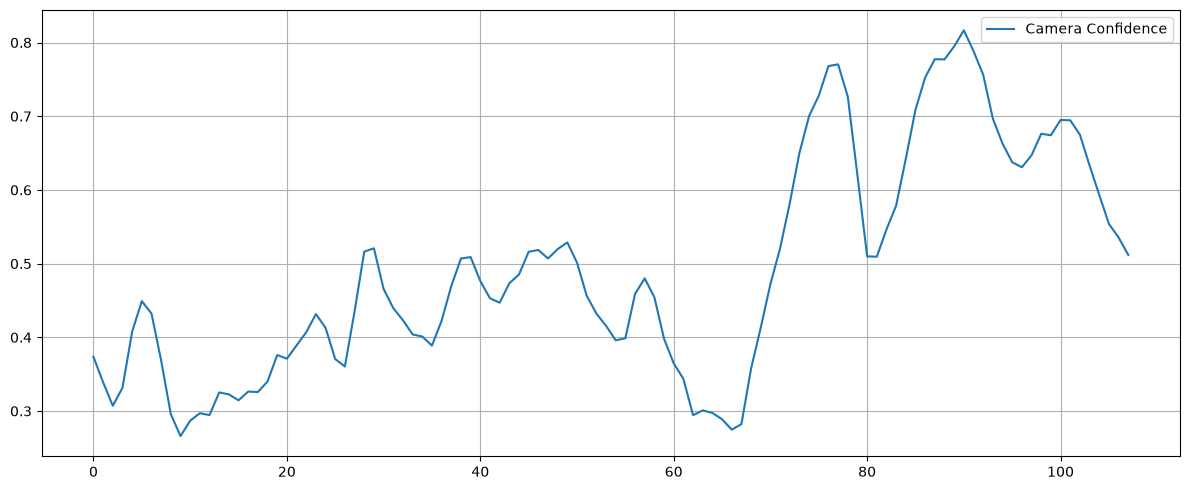

In [4]:
# Cell 4 - Baseline Plot
plt.figure(figsize=(12,5))
plt.plot(confidence_df['Frame'],confidence_df['Camera Confidence'],label='Camera Confidence')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR/'baseline_camera_confidence.png',dpi=300)
plt.show()


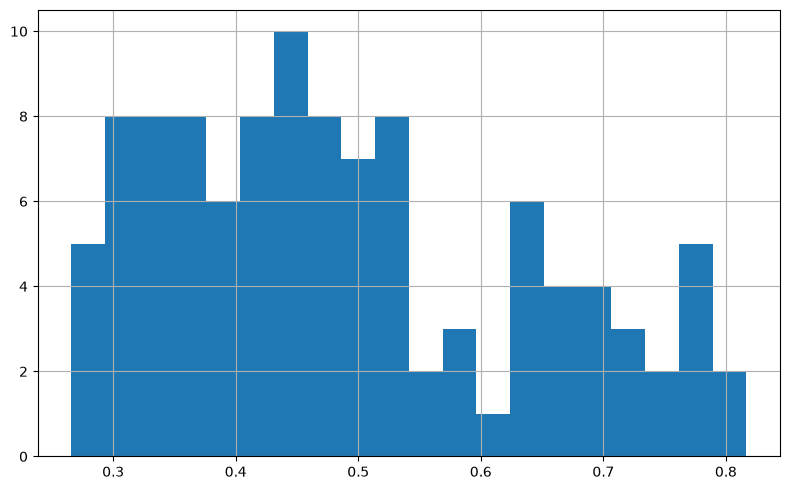

In [5]:
# Cell 5 - Histogram
plt.figure(figsize=(8,5))
plt.hist(confidence_df['Camera Confidence'],bins=20)
plt.grid(True)
plt.tight_layout()
plt.savefig(FIGURE_DIR/'baseline_confidence_distribution.png',dpi=300)
plt.show()


In [6]:
# Cell 6 - Rolling Confidence
WINDOW=5
confidence_df['Rolling Confidence']=confidence_df['Camera Confidence'].rolling(WINDOW,min_periods=1).mean()
display(confidence_df[['Frame','Camera Confidence','Rolling Confidence']].head())


,Frame,Camera Confidence,Rolling Confidence
0,0,0.373539,0.373539
1,1,0.338947,0.356243
2,2,0.307125,0.339870
3,3,0.331519,0.337782
4,4,0.407605,0.351747


In [7]:
# Cell 7 - Temporal Smoothing
ALPHA=0.40
confidence_df['Smoothed Confidence']=confidence_df['Rolling Confidence'].ewm(alpha=ALPHA,adjust=False).mean()
display(confidence_df[['Rolling Confidence','Smoothed Confidence']].head())


,Rolling Confidence,Smoothed Confidence
0,0.373539,0.373539
1,0.356243,0.366620
2,0.339870,0.355920
3,0.337782,0.348665
4,0.351747,0.349898


In [8]:
# Cell 8 - Confidence Stability Index
confidence_df['Confidence Std']=confidence_df['Smoothed Confidence'].rolling(WINDOW,min_periods=1).std().fillna(0)
std=confidence_df['Confidence Std']
confidence_df['Normalized Std']=(std-std.min())/(std.max()-std.min()+1e-8)
confidence_df['Confidence Stability Index']=1-confidence_df['Normalized Std']
display(confidence_df[['Confidence Stability Index']].head())


,Confidence Stability Index
0,1.000000
1,0.939688
2,0.890562
3,0.863707
4,0.866563


In [9]:
# Cell 9 - Sensor Reliability Index
BETA=0.30
confidence_df['Sensor Reliability Index']=(1-BETA)*confidence_df['Smoothed Confidence']+BETA*confidence_df['Confidence Stability Index']
display(confidence_df[['Sensor Reliability Index']].head())


,Sensor Reliability Index
0,0.561477
1,0.538541
2,0.516313
3,0.503178
4,0.504897


In [10]:
# Cell 10 - Camera Adaptive Weight
confidence_df['Camera Adaptive Weight']=confidence_df['Sensor Reliability Index']/confidence_df['Sensor Reliability Index'].max()
display(confidence_df[['Camera Adaptive Weight']].head())


,Camera Adaptive Weight
0,0.713869
1,0.684707
2,0.656446
3,0.639746
4,0.641933


In [11]:
# Cell 11 - Weight Change
confidence_df['Weight Change']=confidence_df['Camera Adaptive Weight'].diff().fillna(0).abs()


In [12]:
# Cell 12 - Statistics
statistics=confidence_df.describe()
summary_table=pd.DataFrame({
'Metric':['Average Confidence','Average SRI','Average Weight'],
'Value':[
confidence_df['Camera Confidence'].mean(),
confidence_df['Sensor Reliability Index'].mean(),
confidence_df['Camera Adaptive Weight'].mean()]
})
display(statistics)
display(summary_table)


,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Rolling Confidence,Smoothed Confidence,Confidence Std,Normalized Std,Confidence Stability Index,Sensor Reliability Index,Camera Adaptive Weight,Weight Change
count,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.00000,108.000000,108.000000,108.000000,108.000000,108.000000,1.080000e+02,108.000000,108.000000,108.000000
mean,0.504872,0.559509,0.422146,0.568500,250.601852,0.375789,0.552321,53.50000,0.490494,0.487208,0.483995,0.021369,0.263458,7.365420e-01,0.559759,0.711685,0.028872
std,0.247358,0.298456,0.281896,0.290495,0.975780,0.316425,0.286485,31.32092,0.148791,0.143208,0.138442,0.017556,0.216450,2.164501e-01,0.092249,0.117287,0.023237
min,0.000000,0.000000,0.000000,0.000000,248.000000,0.000000,0.000000,0.00000,0.265978,0.288022,0.303642,0.000000,0.000000,1.232893e-07,0.394291,0.501306,0.000000
25%,0.306699,0.372807,0.206240,0.276907,250.000000,0.127299,0.267474,26.75000,0.372924,0.372909,0.371520,0.009730,0.119961,6.576270e-01,0.503163,0.639728,0.010022
50%,0.485205,0.558423,0.321661,0.637529,251.000000,0.199340,0.645192,53.50000,0.462247,0.455004,0.446591,0.015889,0.195889,8.041112e-01,0.551926,0.701725,0.023204
75%,0.696022,0.830769,0.694107,0.829450,251.000000,0.696507,0.758943,80.25000,0.599867,0.605418,0.609943,0.027770,0.342373,8.800388e-01,0.618128,0.785896,0.043717
max,1.000000,1.000000,1.000000,1.000000,254.000000,1.000000,1.000000,107.00000,0.816628,0.790853,0.771161,0.081110,1.000000,1.000000e+00,0.786527,1.000000,0.096697


,Metric,Value
0,Average Confidence,0.490494
1,Average SRI,0.559759
2,Average Weight,0.711685


In [13]:
# Cell 13 - Save Results
confidence_df.to_csv(RESULT_DIR/f'dynamic_weight_generation_{DRIVE}.csv',index=False)
statistics.to_csv(RESULT_DIR/f'dynamic_weight_statistics_{DRIVE}.csv')
summary_table.to_csv(RESULT_DIR/f'cadwg_summary_{DRIVE}.csv',index=False)
pd.DataFrame({'Parameter':['WINDOW','ALPHA','BETA'],'Value':[WINDOW,ALPHA,BETA]}).to_csv(
RESULT_DIR/f'cadwg_parameters_{DRIVE}.csv',index=False)
print('Results saved.')


Results saved.


In [14]:
# Cell 14 - Final Summary
print('='*80)
print('NOTEBOOK 06 COMPLETED SUCCESSFULLY')
print('='*80)
print('Frames:',len(confidence_df))
print('Average Weight:',round(confidence_df['Camera Adaptive Weight'].mean(),3))
print('READY FOR NOTEBOOK 07')


NOTEBOOK 06 COMPLETED SUCCESSFULLY
Frames: 108
Average Weight: 0.712
READY FOR NOTEBOOK 07
